# From a Training Loop to a Production RL Setup

*Take the GRPO training loop from the previous article apart into the pieces a production RL setup is built from: an inference engine, weight synchronisation, a batch that travels between processes, and worker groups. Break each one on purpose to see why it exists, then hand the whole loop to verl.*

## Motivation

In the [previous article](grpo_manual.ipynb), we built a GRPO training loop in plain PyTorch and trained a model with it. A production RL setup doesn't look like that loop. Generation runs in a separate inference engine, the weights are copied over to it after every update, the work is split across processes and GPUs, and a framework with hundreds of config options coordinates it all.

Each of those pieces exists because something goes wrong without it. So, in this article, rather than describing each piece, we'll take it away (or set it up wrongly) and watch what happens, before putting it back and comparing our version with verl's.

We'll answer these questions:

1. Why does a production setup generate with a separate inference engine, and what can go wrong when it does? (§1)
2. What happens if the inference engine's weights fall behind the model we're training? (§2)
3. The inference engine already gives us log-probs; why are they computed again? (§3)
4. What can go wrong when a batch is reordered or split up? (§4)
5. Why are the roles split into separate processes, and how is the work spread across many workers? (§5)
6. What does a real framework's run look like, and what do its settings actually count? (§6)

We'll keep the task, the model and the algorithm from the previous article (three-term arithmetic, Qwen2.5-0.5B-Instruct and GRPO), so anything that changes here is down to *how* the training is run, not *what* is trained. We'll also keep coming back to the question we followed for most of the previous article, "What is 19 × 99 + 10?", and look at what each change does to its group of 8 samples.

**What we need to know already.** The previous article: log-probs (§1.3), GRPO advantages (§1.5–§1.6), the batch layout (§1.7), π_old and PPO's clipped loss (§1.9), and verl's versions of our functions (§2). Its code is imported here from `tutorial/lib/rl_core.py`.

**Hardware and time.** One GPU with about 80 GB, and about 7 minutes on an H100.

## 0. Setup

In [1]:
import gc
import html
import json
import os
import random
import re
import shutil
import subprocess
import sys
import time
from pathlib import Path

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "examples" / "calc_x").is_dir())
sys.path.insert(0, str(REPO / "tutorial/lib"))  # shared code: paths, the model name, the seed
from common import DEVICE, GENERATED, MODEL, SEED, SHM, WORK, follow_log, gpu_free_gib, log_tail, setup, start_service  # noqa: E402

os.environ["VLLM_LOGGING_LEVEL"] = "ERROR"  # vLLM's warnings would bury the outputs
os.environ["TQDM_DISABLE"] = "1"  # and so would the progress bars of vLLM, datasets and verl (child processes inherit this)
setup()  # creates the working folders, seeds the random number generators, checks the GPU is free

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import torch  # noqa: E402
from IPython.display import HTML, display  # noqa: E402
from transformers import AutoTokenizer  # noqa: E402
from verl.trainer.ppo.core_algos import compute_grpo_outcome_advantage  # noqa: E402
from vllm import LLM, SamplingParams, TokensPrompt  # noqa: E402

from arith_task import BOXED, reward_fn  # noqa: E402
from rl_core import (EVAL, INSTRUCTION, LR, PAD_ID, STOP_IDS, TRAIN, chat_prompt_ids, compute_log_probs, decode_tokens,  # noqa: E402
                     evaluate, grpo_advantages, hf_generate, load_policy, make_optimizer, make_padded_batch, plot_histories,
                     ppo_update, print_step_metrics, tokenizer, verl_ppo_loss)

repo: /home/azureuser/localfiles/agl-rl-tutorials
python: /home/azureuser/localfiles/agl-rl-tutorials/.venv/bin/python
GPU: NVIDIA H100 NVL, 92 of 93 GiB free


#### Two ways of looking at a training step

We'll use two small tools throughout, so that every change in this article can be seen the same way.

The first, `show_group`, prints a group of samples one per line, with its reward, and can colour each token by a number: how unlikely it was, or how much two models disagree about it. The second, `plot_step_times`, draws where the seconds of a training step went, so that we can compare setups at a glance.

In [2]:
def show_group(samples: list[dict], rewards: list[float], token_values: list[list[float]] | None = None,
               full_colour_at: float = 1.0, title: str = "", max_tokens: int = 70) -> None:
    # One line per sample: its reward, then its first max_tokens tokens.
    # If token_values is given, each token's background is coloured in proportion to its value (full red at full_colour_at)
    lines = []
    for sample_idx, sample in enumerate(samples):
        token_spans = []
        for position, token_id in enumerate(sample["response_ids"][:max_tokens]):
            token_text = html.escape(tokenizer.decode([token_id])).replace("\n", "↵")
            colour_strength = 0.0
            if token_values is not None:
                colour_strength = min(abs(token_values[sample_idx][position]) / full_colour_at, 1.0)
            token_spans.append(f'<span style="background: rgba(220, 60, 30, {colour_strength:.2f})">{token_text}</span>')
        reward_badge = "✅" if rewards[sample_idx] == 1 else "❌"
        lines.append(f"<div>{reward_badge} {''.join(token_spans)}{' …' if len(sample['response_ids']) > max_tokens else ''}</div>")
    heading = f"<b>{title}</b>" if title else ""
    display(HTML(f'{heading}<div style="font-family: monospace; font-size: 12px; line-height: 1.6">{"".join(lines)}</div>'))


def plot_step_times(histories: dict[str, list[dict]]) -> None:
    # One horizontal bar per setup: the average seconds per step spent in each stage (the metrics named "time/...")
    stage_colours = {"gen": "tab:blue", "old_log_prob": "tab:orange", "reward": "tab:purple", "update": "tab:green", "sync": "tab:red"}
    fig, ax = plt.subplots(figsize=(10, 0.7 * len(histories) + 0.8))
    for row, (setup_name, history) in enumerate(histories.items()):
        left = 0.0
        for stage, colour in stage_colours.items():
            seconds = np.mean([metrics.get(f"time/{stage}", 0.0) for metrics in history])
            label = stage if row == 0 else None
            ax.barh(row, seconds, left=left, color=colour, label=label)
            if seconds > 0.25:
                ax.text(left + seconds / 2, row, f"{seconds:.1f}", ha="center", va="center", color="white", fontsize=9)
            left += seconds
    ax.set_yticks(range(len(histories)), list(histories))
    ax.invert_yaxis()
    ax.set_xlabel("seconds per training step")
    ax.legend(loc="lower right", ncols=5, fontsize=8)
    plt.tight_layout()
    plt.show()

In [3]:
FOLLOWED = TRAIN[0]  # the question we followed through the previous article
followed_prompt = chat_prompt_ids(FOLLOWED["question"])


def group_rewards(samples: list[dict], answer: int) -> list[float]:
    return [reward_fn(decode_tokens(sample["response_ids"]), answer) for sample in samples]


FOLLOWED

{'question': 'What is 19 * 99 + 10?', 'answer': 1891}

## 1. A separate inference engine

Let's start where the previous article ended: our training loop, generating with Hugging Face's `generate`. We'll run two of its training steps (with `rl_step` from the previous article's §2, and 16 questions × 8 samples per step), and see where the time goes.

We keep a copy of the original weights, so that we can go back to them later.

In [4]:
import rl_core  # the previous article's training step, as rl_core.rl_step

policy = load_policy()  # Qwen2.5-0.5B-Instruct, the original weights
optimizer = make_optimizer(policy, LR)
original_weights = {name: tensor.detach().cpu().clone() for name, tensor in policy.state_dict().items()}

In [5]:
QUESTIONS_PER_STEP = 16
hf_history = []
for step in range(2):
    problems = TRAIN[1 + step * QUESTIONS_PER_STEP : 1 + (step + 1) * QUESTIONS_PER_STEP]
    metrics, _, _ = rl_core.rl_step(policy, optimizer, lambda prompts, n: hf_generate(policy, prompts, n), problems)
    hf_history.append(metrics)
    print_step_metrics(step, metrics)

step  0 | reward 0.570 | format 0.80 | len 146.2 | grad_norm 2.271 | gen  7.1s old_log_prob  0.3s update  2.4s


step  1 | reward 0.547 | format 0.78 | len 159.5 | grad_norm 1.953 | gen  6.9s old_log_prob  0.3s update  2.4s


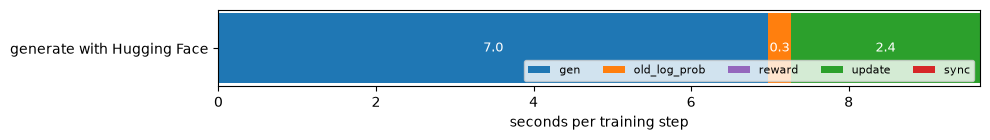

In [6]:
plot_step_times({"generate with Hugging Face": hf_history})

Generation takes about 7 of the roughly 10 seconds of each step. And this is a small model writing short answers: for a production model writing thousands of tokens per response, or an agent working over many turns, the gap only grows. This is why every production RL setup hands generation to a dedicated **inference engine**, such as [vLLM](https://docs.vllm.ai) or [SGLang](https://docs.sglang.ai); here, we'll use vLLM.

`model.generate` moves the whole batch forward together, one token per step, until the longest response is finished. Here it is for three sequences, where each square is one generated token:

![Static batching: once B and C finish, their slots sit idle until A, the longest response, is done](images/static_batching.png)

Rows that finish early sit idle, each row's key/value cache is reserved up front for the longest possible response, and each new token launches hundreds of small GPU kernels from Python. vLLM fixes all three: **continuous batching** gives a finished row's slot to a waiting sequence straight away, **PagedAttention** hands out KV-cache memory in small blocks as each sequence grows, and **CUDA graphs** replay each decoding step's GPU work without the Python overhead:

![Continuous batching: D and E take over the slots as soon as B and C finish, so no slot sits idle](images/continuous_batching.png)

To do this, vLLM loads the checkpoint into its own implementation of the model, with its own kernels, in bf16. So, as soon as we use it, there are **two copies of the weights**: the one we train, and the one vLLM generates with. Most of this article is about what that second copy changes.

Let's start a vLLM engine on the same GPU, with 30% of its memory for its weights and KV cache. (`enable_sleep_mode` lets us free that memory later, in §5.)

In [7]:
llm = LLM(model=MODEL, gpu_memory_utilization=0.3, max_model_len=4096, seed=SEED, enable_sleep_mode=True)

#### What vLLM gives back

Let's ask vLLM for 8 samples of our followed question, with the RL sampling settings from §1.2 of the previous article, plus `logprobs=0`, which asks it to also return the log-prob of each token it sampled (the number is how many *extra* alternatives to return, so 0 means none):

In [8]:
rl_sampling = SamplingParams(n=8, temperature=1.0, top_p=1.0, top_k=0, repetition_penalty=1.0, max_tokens=256, logprobs=0)
request_outputs = llm.generate([TokensPrompt(prompt_token_ids=followed_prompt)], rl_sampling, use_tqdm=False)

print(f"{len(request_outputs)} request output (one per prompt), holding {len(request_outputs[0].outputs)} completions")

1 request output (one per prompt), holding 8 completions


In [9]:
completion = request_outputs[0].outputs[0]
print("first 5 sampled tokens:", completion.token_ids[:5])
print("log-probs at the first 2 positions:", completion.logprobs[:2])

first 5 sampled tokens: [1249, 11625, 279, 7493, 17767]
log-probs at the first 2 positions: [{1249: Logprob(logprob=-0.48460888862609863, rank=1, decoded_token='To')}, {11625: Logprob(logprob=-0.03357545658946037, rank=1, decoded_token=' solve')}]


Each completion holds the sampled token IDs, and one dict per position, keyed by the sampled token's ID. This gives us something `hf_generate` never did: the log-prob of every token, recorded as it was sampled. `vllm_generate` unpacks this into the same sample format as `hf_generate`, so that the rest of our training loop doesn't change:

In [10]:
def vllm_generate(llm, prompts: list[list[int]], samples_per_prompt: int, max_tokens: int = 256, temperature: float = 1.0) -> list[dict]:
    # logprobs=0: return the log-prob of each sampled token (and no alternatives)
    params = SamplingParams(n=samples_per_prompt, temperature=temperature, top_p=1.0, top_k=0, repetition_penalty=1.0, max_tokens=max_tokens, logprobs=0)
    
    token_prompts = [TokensPrompt(prompt_token_ids=prompt) for prompt in prompts]
    request_outputs = llm.generate(token_prompts, params, use_tqdm=False)
    samples = []
    
    for prompt, request_output in zip(prompts, request_outputs):
        for completion in request_output.outputs:  # samples_per_prompt completions per prompt
            response_ids = list(completion.token_ids)
            
            # completion.logprobs holds one {token_id: Logprob} dict per position; look up the token that was sampled
            log_probs = []
            
            for token_id, logprobs_at_position in zip(response_ids, completion.logprobs):
                log_probs.append(logprobs_at_position[token_id].logprob)
            
            samples.append({"prompt_ids": list(prompt), "response_ids": response_ids, "log_probs": log_probs})
    
    return samples

In [11]:
prompts = [chat_prompt_ids(problem["question"]) for problem in TRAIN[1:17]]

start = time.time()
hf_samples = hf_generate(policy, prompts, samples_per_prompt=8)
print(f"hf_generate:   {len(hf_samples)} samples in {time.time() - start:5.2f}s")

start = time.time()
vllm_samples = vllm_generate(llm, prompts, samples_per_prompt=8)
print(f"vllm_generate: {len(vllm_samples)} samples in {time.time() - start:5.2f}s")

hf_generate:   128 samples in  6.76s


vllm_generate: 128 samples in  0.81s


vLLM generated the same 128 samples about 8 times faster (0.8 s against 6.8 s), and the gap grows with the batch size: a production step often generates thousands of samples.

#### Is vLLM sampling from our policy?

In the previous article (§1.2), `generate` silently took any sampling parameter we didn't pass from the model's `generation_config.json`: for Qwen2.5-0.5B-Instruct, `temperature=0.7, top_p=0.8, top_k=20, repetition_penalty=1.1`. vLLM does the same thing:

In [12]:
llm.get_default_sampling_params()

SamplingParams(n=1, presence_penalty=0.0, frequency_penalty=0.0, repetition_penalty=1.1, temperature=0.7, top_p=0.8, top_k=20, min_p=0.0, seed=None, stop=[], stop_token_ids=[], bad_words=[], thinking_token_budget=None, include_stop_str_in_output=False, ignore_eos=False, max_tokens=16, min_tokens=0, logprobs=None, prompt_logprobs=None, skip_special_tokens=True, spaces_between_special_tokens=True, structured_outputs=None, extra_args=None)

These are what vLLM samples with whenever a request doesn't say otherwise: `llm.generate` called without sampling settings, or, more often, a request to a vLLM *server* that leaves them out. (A `SamplingParams` we build ourselves starts from vLLM's own neutral defaults instead, which is why `vllm_generate` still sets every one of them explicitly.)

So, what changes if they slip through? `top_k=20` means that a token outside π's 20 most likely next tokens can never be sampled, and `top_p=0.8` cuts the unlikely tail further. To see what this does, let's sample our followed question both ways, and colour red every token that the model we train gave a probability below 5%: its unlikely choices.

`token_probabilities` scores the sampled tokens with our training model, in the same way as `compute_log_probs`, and returns each token's probability:

In [13]:
def token_probabilities(samples: list[dict]) -> list[list[float]]:
    # π(token) for every sampled token, under the model we train
    batch = make_padded_batch([sample["prompt_ids"] for sample in samples], [sample["response_ids"] for sample in samples])
    log_probs = compute_log_probs(policy, batch)
    probabilities = []
    for row, sample in enumerate(samples):
        num_tokens = len(sample["response_ids"])
        probabilities.append(log_probs[row, :num_tokens].exp().tolist())
    return probabilities

In [14]:
chat_settings = llm.get_default_sampling_params()  # what a request that sets nothing gets: the model's chat defaults
chat_settings.n, chat_settings.max_tokens, chat_settings.seed = 8, 256, 1
rl_settings = SamplingParams(n=8, temperature=1.0, top_p=1.0, top_k=0, repetition_penalty=1.0, max_tokens=256, seed=1)

samples_by_setting = {}
for setting_name, settings in [("chat defaults", chat_settings), ("RL settings", rl_settings)]:
    outputs = llm.generate([TokensPrompt(prompt_token_ids=followed_prompt)], settings, use_tqdm=False)
    samples_by_setting[setting_name] = [{"prompt_ids": followed_prompt, "response_ids": list(c.token_ids)} for c in outputs[0].outputs]

In [15]:
for setting_name, samples in samples_by_setting.items():
    is_unlikely = [[1.0 if p < 0.05 else 0.0 for p in sample_probs] for sample_probs in token_probabilities(samples)]
    show_group(samples, group_rewards(samples, FOLLOWED["answer"]), is_unlikely, title=f"{setting_name}: red = π gave this token less than 5%")

By eye, the two groups look much the same: the model's unlikely choices are rare either way, and the first 70 tokens of each sample hold at most two of them. To put a number on it, let's sample 64 responses each way and count how many sampled tokens π gives a probability below 5%:

In [16]:
counts = []
for setting_name, settings in [("chat defaults", chat_settings), ("RL settings", rl_settings)]:
    settings = settings.clone()
    settings.n = 64
    outputs = llm.generate([TokensPrompt(prompt_token_ids=followed_prompt)], settings, use_tqdm=False)
    samples = [{"prompt_ids": followed_prompt, "response_ids": list(c.token_ids)} for c in outputs[0].outputs]
    all_probabilities = np.concatenate([np.array(p) for p in token_probabilities(samples)])
    counts.append({
        "sampling": setting_name,
        "tokens per response": round(len(all_probabilities) / len(samples), 1),
        "π(token) < 5%": f"{(all_probabilities < 0.05).mean():.2%}",
        "π(token) < 20%": f"{(all_probabilities < 0.2).mean():.2%}",
        "mean log π per token": round(float(np.log(all_probabilities).mean()), 3),
    })
pd.DataFrame(counts).set_index("sampling")

,tokens per response,π(token) < 5%,π(token) < 20%,mean log π per token
sampling,,,,
chat defaults,148.8,0.43%,1.32%,-0.112
RL settings,178.1,2.25%,5.26%,-0.263


Counted, the difference is large. With the chat defaults, 0.43% of the sampled tokens have π < 5%; with the RL settings, 2.25%, about 5 times as many. The chat-default responses are also shorter (149 tokens against 178), and their mean log π per token is much higher (−0.11 against −0.26): they are made of the tokens that π likes best. Those low-probability tokens are the model's real *choices*, where, as we saw in §1.3 of the previous article, the learning happens. With the chat defaults, the model is never shown what happens when it makes them, and the samples it does see are made of tokens that π finds more likely than they really are, so the update is tuned for a model we don't have.

So, we always pass the RL settings explicitly, as `vllm_generate` does. Production frameworks do the same: verl overrides the generation config when it starts vLLM, and a vLLM *server* needs `--generation-config vllm` to ignore the model's defaults.

## 2. Keeping the weights in sync

We now have two copies of the weights. Our training loop updates its copy, but vLLM's copy never changes on its own. What happens if we forget about it?

Our training step is the previous article's `rl_step`, with one addition at the end: as vLLM gives us its own log-prob for every token it sampled, we compare them with the log-probs our training model computes for π_old, and report the average difference as `logp_mismatch`:

In [17]:
def rl_step(policy, optimizer, generate, problems, samples_per_prompt: int = 8, **update_kwargs) -> tuple[dict, dict, list[dict]]:
    timing = {}

    # 1. Sample several responses per problem (a GRPO group). Samples are prompt-major: sample i answers problem i // samples_per_prompt
    start = time.time()
    samples = generate([chat_prompt_ids(problem["question"]) for problem in problems], samples_per_prompt)
    timing["gen"] = time.time() - start
    group_ids = [i // samples_per_prompt for i in range(len(samples))]

    # 2. Score each response, then pad everything into one batch (for π_old, the advantages and the update)
    texts = [decode_tokens(sample["response_ids"]) for sample in samples]
    rewards = torch.tensor([reward_fn(text, problems[group]["answer"]) for text, group in zip(texts, group_ids)])
    batch = make_padded_batch([sample["prompt_ids"] for sample in samples], [sample["response_ids"] for sample in samples])

    # π_old: log-probs under the weights that generated the samples (§1.9)
    start = time.time()
    old_log_probs = compute_log_probs(policy, batch)
    timing["old_log_prob"] = time.time() - start

    # 3. Advantages with verl's GRPO estimator, which takes each response's reward on its last token
    last_token = batch["response_mask"].sum(-1).clamp(min=1) - 1
    token_level_rewards = torch.zeros(batch["response_mask"].shape)
    token_level_rewards[torch.arange(len(samples)), last_token] = rewards
    
    advantages, _ = compute_grpo_outcome_advantage(
        token_level_rewards=token_level_rewards, response_mask=batch["response_mask"], index=np.array(group_ids, dtype=object),
    )
    batch.update(old_log_probs=old_log_probs, advantages=advantages)  # kept for inspection after the update

    # 4. Update: PPO, with verl's loss
    start = time.time()
    stats = ppo_update(policy, optimizer, batch, old_log_probs, advantages, loss_fn=verl_ppo_loss, **update_kwargs)
    timing["update"] = time.time() - start

    metrics = {
        "reward": rewards.mean().item(),
        "format": float(np.mean([bool(BOXED.search(text)) for text in texts])),  # has a \boxed{integer} at all, right or wrong
        "response_len": batch["response_mask"].sum(-1).float().mean().item(),
        **stats,
    }
    
    if samples[0]["log_probs"] is not None:  # the inference engine returned its own log-probs: compare them with ours
        engine_log_probs = torch.zeros_like(old_log_probs)
    
        for row, sample in enumerate(samples):
            engine_log_probs[row, : len(sample["log_probs"])] = torch.tensor(sample["log_probs"])
    
        trained = batch["response_mask"].bool()
        metrics["logp_mismatch"] = (old_log_probs - engine_log_probs)[trained].abs().mean().item()
    
    metrics.update({f"time/{name}": seconds for name, seconds in timing.items()})
    
    return metrics, batch, samples

Let's go back to the original weights, which vLLM also has, and train for 6 steps without telling vLLM about any of the updates:

In [18]:
policy.load_state_dict(original_weights)
optimizer = make_optimizer(policy, LR)


def vllm_sample(prompts, samples_per_prompt):
    return vllm_generate(llm, prompts, samples_per_prompt)

In [19]:
question_rng = random.Random(SEED)  # which training questions each step uses
stale_steps = []  # each step's batch and samples, kept for §3
for step in range(6):
    problems = question_rng.sample(TRAIN, QUESTIONS_PER_STEP)
    metrics, batch, samples = rl_step(policy, optimizer, vllm_sample, problems)  # no weight sync: vLLM keeps the original weights
    stale_steps.append((batch, samples))
    print_step_metrics(step, metrics)

step  0 | reward 0.578 | format 0.86 | len 146.9 | grad_norm 2.717 | logp mismatch 0.0095 | gen  0.7s old_log_prob  0.3s update  2.3s


step  1 | reward 0.594 | format 0.81 | len 152.0 | grad_norm 2.523 | logp mismatch 0.0107 | gen  0.7s old_log_prob  0.3s update  2.5s


step  2 | reward 0.539 | format 0.80 | len 152.5 | grad_norm 2.180 | logp mismatch 0.0188 | gen  0.7s old_log_prob  0.3s update  2.3s


step  3 | reward 0.500 | format 0.79 | len 151.5 | grad_norm 2.494 | logp mismatch 0.0385 | gen  0.7s old_log_prob  0.3s update  2.6s


step  4 | reward 0.672 | format 0.85 | len 138.9 | grad_norm 2.584 | logp mismatch 0.0522 | gen  0.7s old_log_prob  0.3s update  2.3s


step  5 | reward 0.578 | format 0.80 | len 150.1 | grad_norm 2.773 | logp mismatch 0.0679 | gen  0.7s old_log_prob  0.3s update  2.3s


Nothing crashes, and the reward and loss look ordinary. The only number that moves is `logp_mismatch`: from 0.0095 at step 0 to 0.068 at step 5, seven times as large. To see what that means, let's sample our followed question with the stale engine and colour each token by how much the two copies now disagree about it, |log π (training model) − log π (vLLM)|, with full red at a difference of 0.5:

In [20]:
def token_disagreement(samples: list[dict]) -> list[list[float]]:
    # |log π (training model) − log π (vLLM)| for every sampled token
    batch = make_padded_batch([sample["prompt_ids"] for sample in samples], [sample["response_ids"] for sample in samples])
    training_log_probs = compute_log_probs(policy, batch)
    differences = []
    for row, sample in enumerate(samples):
        num_tokens = len(sample["response_ids"])
        engine_log_probs = torch.tensor(sample["log_probs"])
        differences.append((training_log_probs[row, :num_tokens] - engine_log_probs).abs().tolist())
    return differences

In [21]:
stale_group = vllm_generate(llm, [followed_prompt], 8)
show_group(stale_group, group_rewards(stale_group, FOLLOWED["answer"]), token_disagreement(stale_group), full_colour_at=0.5,
           title="vLLM 6 updates behind: red = the two copies disagree")

Every sample has red tokens: between 7 and 25 of its first 70 tokens are ones where the two copies now disagree by more than 0.15 in log-prob. These are tokens whose probability training has moved, while vLLM still samples them as the original model would. Every one of those samples came from a policy that no longer exists, but the update treats them as samples from the current one. Notice that the clipped loss can't catch this either: π_old is computed by our training model, so the ratio is exactly 1 before every first update. `logp_mismatch` is the only thing that tells us.

#### Pushing the weights

The fix is to copy the weights to vLLM after every update. The simplest way has two parts:

1. The **data plane**, which moves the bytes: the training loop writes its weights to a file, in the Hugging Face checkpoint format. We use `/dev/shm`, which Linux keeps in RAM, and convert to bf16 on the way, as that is what vLLM computes in.
2. The **control plane**, a small message that says "new weights are ready, and this is where they are": `collective_rpc("reload_weights", ...)`.

There is one more detail. vLLM's **prefix cache** reuses the key/value cache for prompt prefixes it has seen before, and all our prompts start with the same system prompt. Those cached values were computed with the old weights, so after loading new ones, we reset the cache too.

In [22]:
import safetensors.torch

def push_weights(model, llm) -> None:
    weights_path = save_for_inference(model)                                     # 1. data plane: write the weights to RAM
    llm.collective_rpc("reload_weights", kwargs={"weights_path": weights_path})  # 2. control plane: tell vLLM to load them
    llm.reset_prefix_cache()  # cached KV values were computed with the old weights


def save_for_inference(model, path: Path = SHM / "policy") -> str:
    path.mkdir(parents=True, exist_ok=True)
    state = {}
    
    for name, tensor in model.state_dict().items():
        state[name] = tensor.detach().to(torch.bfloat16).cpu().contiguous()  # a bf16 copy on the CPU, ready to write
    
    if model.config.tie_word_embeddings:
        state.pop("lm_head.weight", None)  # same tensor as the embedding; vLLM ties them itself
    
    safetensors.torch.save_file(state, str(path / "model.safetensors"))
    return str(path)

In [23]:
push_weights(policy, llm)

synced_group = vllm_generate(llm, [followed_prompt], 8)
show_group(synced_group, group_rewards(synced_group, FOLLOWED["answer"]), token_disagreement(synced_group), full_colour_at=0.5,
           title="vLLM synced: red = the two copies disagree")

With the weights pushed, the red is gone: in the first 70 tokens of all 8 samples, no token differs by more than 0.15. (A few faint ones remain; §3 is about those.)

Production frameworks follow the same structure, but skip the round trip through the CPU: verl, for example, sends the bf16 tensors straight from the training GPUs' memory to vLLM's, over CUDA IPC when both are on the same GPU, or NCCL when they aren't, in fixed-size buckets.

#### Training with vLLM generating

Now let's train properly: from the original weights, for 20 steps of 16 questions × 8 samples, pushing the weights after every step, and timing the push as `sync`:

In [24]:
policy.load_state_dict(original_weights)
optimizer = make_optimizer(policy, LR)
push_weights(policy, llm)


def vllm_greedy(prompts, samples_per_prompt):
    return vllm_generate(llm, prompts, samples_per_prompt, temperature=0.0)  # temperature 0: always the most likely token


accuracy_before = evaluate(vllm_greedy)

In [25]:
NUM_STEPS = 20
question_rng = random.Random(SEED)  # the same questions as the stale run above
vllm_history = []
for step in range(NUM_STEPS):
    problems = question_rng.sample(TRAIN, QUESTIONS_PER_STEP)
    metrics, batch, samples = rl_step(policy, optimizer, vllm_sample, problems)

    start = time.time()
    push_weights(policy, llm)  # vLLM must generate the next step's samples with the new weights
    metrics["time/sync"] = time.time() - start

    vllm_history.append(metrics)
    print_step_metrics(step, metrics)

step  0 | reward 0.586 | format 0.85 | len 148.8 | grad_norm 2.683 | logp mismatch 0.0098 | gen  0.7s old_log_prob  0.3s update  2.3s sync  1.4s


step  1 | reward 0.625 | format 0.84 | len 156.3 | grad_norm 2.158 | logp mismatch 0.0082 | gen  0.7s old_log_prob  0.3s update  2.3s sync  1.4s


step  2 | reward 0.570 | format 0.84 | len 159.3 | grad_norm 1.970 | logp mismatch 0.0078 | gen  0.7s old_log_prob  0.3s update  2.2s sync  1.3s


step  3 | reward 0.539 | format 0.83 | len 160.2 | grad_norm 2.119 | logp mismatch 0.0075 | gen  0.8s old_log_prob  0.3s update  2.3s sync  1.4s


step  4 | reward 0.727 | format 0.91 | len 143.6 | grad_norm 2.833 | logp mismatch 0.0080 | gen  0.6s old_log_prob  0.3s update  2.3s sync  1.4s


step  5 | reward 0.727 | format 0.94 | len 142.4 | grad_norm 1.908 | logp mismatch 0.0071 | gen  0.8s old_log_prob  0.3s update  2.3s sync  1.4s


... (10 outputs left out)

step 16 | reward 0.750 | format 1.00 | len 116.1 | grad_norm 1.907 | logp mismatch 0.0068 | gen  0.7s old_log_prob  0.3s update  2.3s sync  1.4s


step 17 | reward 0.727 | format 1.00 | len 108.8 | grad_norm 2.360 | logp mismatch 0.0067 | gen  0.5s old_log_prob  0.3s update  2.2s sync  1.4s


step 18 | reward 0.883 | format 0.99 | len 111.0 | grad_norm 1.645 | logp mismatch 0.0069 | gen  0.5s old_log_prob  0.3s update  2.2s sync  1.4s


step 19 | reward 0.664 | format 1.00 | len 121.1 | grad_norm 1.453 | logp mismatch 0.0066 | gen  0.6s old_log_prob  0.3s update  2.2s sync  1.4s


In [26]:
accuracy_after = evaluate(vllm_greedy)
print(f"\ngreedy accuracy on {len(EVAL)} held-out problems: {accuracy_before:.3f} before -> {accuracy_after:.3f} after {NUM_STEPS} steps")


greedy accuracy on 200 held-out problems: 0.760 before -> 0.830 after 20 steps


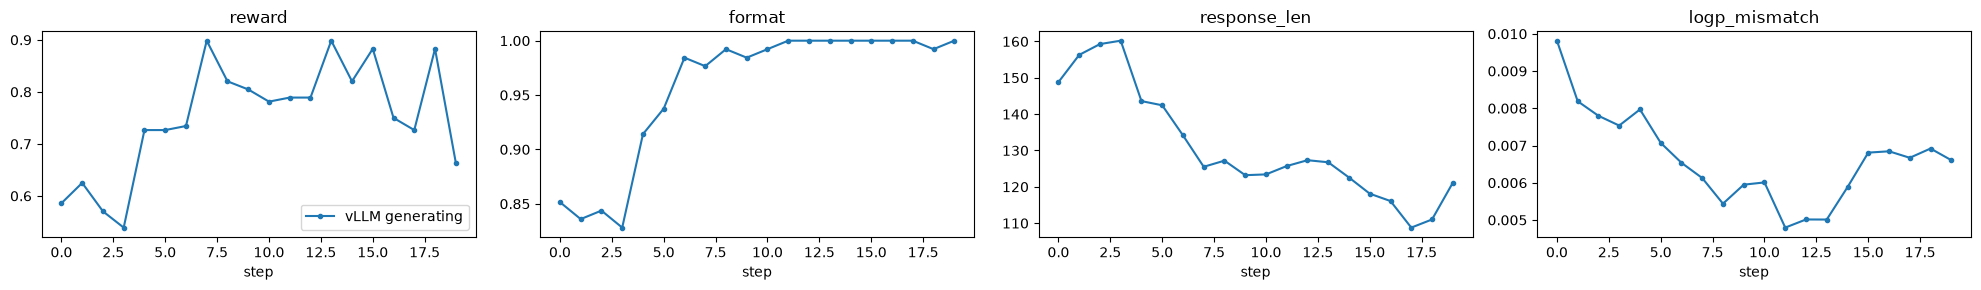

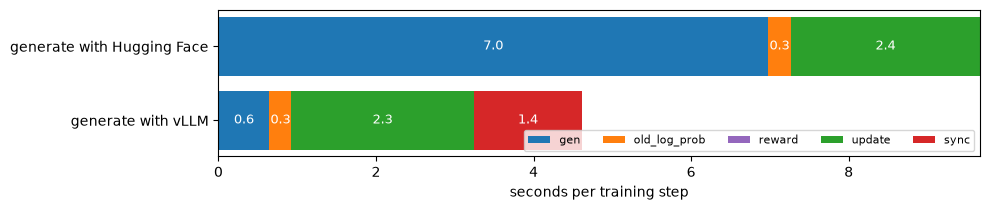

In [27]:
plot_histories({"vLLM generating": vllm_history}, keys=("reward", "format", "response_len", "logp_mismatch"))
plot_step_times({"generate with Hugging Face": hf_history, "generate with vLLM": vllm_history})

`logp_mismatch` now stays between about 0.004 and 0.010 for all 20 steps, instead of climbing. The reward rises from about 0.6 to around 0.8–0.9, noisily, and greedy accuracy on the 200 held-out questions went from 0.760 to 0.830. Notice that the format rises first: within 7 steps, the share of responses with a `\boxed{}` number went from 0.85 to 0.98, and as a response without one always scores 0, that accounts for much of the early rise in reward. This is a common pattern in RL: the model first learns whatever the reward checks most directly.

The step-time bar shows where the time went: generation shrank from about 7 s to under 1 s per step, so the update (about 2.3 s) is now the biggest part, followed by the weight sync (about 1.4 s), which didn't exist before. Moving generation out of the training loop doesn't make the step free; it moves the cost around, and adds a new one.

## 3. Why compute the log-probs again?

vLLM gives us the log-prob of every token it samples, and `rl_step` then computes π_old again with the training model (`compute_log_probs`). That's a whole extra forward pass over the batch. Why not use vLLM's numbers?

Even with the weights in sync, the faint red tokens in §2 tell us that the two copies don't agree exactly. Let's look at every token of the last training batch:

In [28]:
trained = batch["response_mask"].bool()

# vLLM's log-prob of every sampled token, padded to the same shape as the batch
engine_log_probs = torch.zeros_like(batch["old_log_probs"])
for row, sample in enumerate(samples):
    engine_log_probs[row, : len(sample["log_probs"])] = torch.tensor(sample["log_probs"])

difference = (batch["old_log_probs"] - engine_log_probs)[trained]  # log π (training model) − log π (vLLM), one per trained token
print(f"{difference.numel()} trained tokens")
print(f"mean |difference|:            {difference.abs().mean():.4f}")
print(f"99th percentile |difference|: {difference.abs().quantile(0.99):.3f}")
print(f"largest |difference|:         {difference.abs().max():.3f}")

15500 trained tokens
mean |difference|:            0.0066
99th percentile |difference|: 0.115
largest |difference|:         0.375


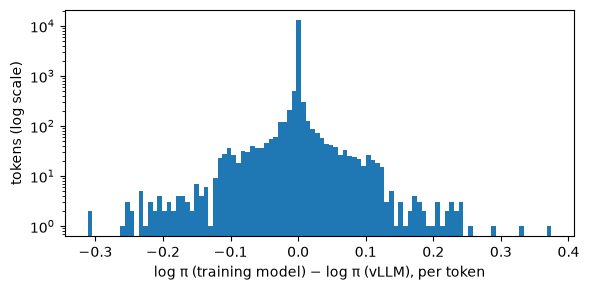

In [29]:
plt.figure(figsize=(6, 3))
plt.hist(difference.numpy(), bins=100, log=True)
plt.xlabel("log π (training model) − log π (vLLM), per token")
plt.ylabel("tokens (log scale)")
plt.tight_layout()
plt.show()

Most tokens agree almost exactly (the mean difference is 0.007), but there is a long tail: in our run, 1 token in 100 was off by 0.115 or more, and the worst by 0.375. This isn't a bug in either program: vLLM and our training model use different GPU kernels, which add numbers up in a different order, and bf16 keeps only about 3 significant digits (§1.7 of the previous article), so the rounding comes out differently.

#### What if we used vLLM's numbers as π_old?

Before the first update, the ratio ρ = π_θ / π_old (§1.9 of the previous article) should be exactly 1 for every token, as nothing has changed yet. With vLLM's numbers as π_old, it would be e^(difference) instead. Let's count the tokens in the last batch where that ratio is already outside the clip range in the direction the advantage wants, so that the clip would set their gradient to zero before the model has moved at all:

In [30]:
def blocked_by_clip(batch, samples, clip_low: float = 0.2, clip_high: float = 0.28):
    # Which tokens would the clip block before any update, if vLLM's log-probs were used as π_old?
    trained = batch["response_mask"].bool()
    engine_log_probs = torch.zeros_like(batch["old_log_probs"])
    for row, sample in enumerate(samples):
        engine_log_probs[row, : len(sample["log_probs"])] = torch.tensor(sample["log_probs"])

    ratio = torch.exp(batch["old_log_probs"] - engine_log_probs)  # what ρ would be before the first update
    token_advantages = batch["advantages"]
    pushed_up_too_far = (token_advantages > 0) & (ratio > 1 + clip_high)
    pushed_down_too_far = (token_advantages < 0) & (ratio < 1 - clip_low)
    blocked = (pushed_up_too_far | pushed_down_too_far) & trained
    has_signal = trained & (token_advantages != 0)
    return blocked, has_signal, engine_log_probs, ratio

In [31]:
blocked, has_signal, engine_log_probs, ratio_if_engine_were_pi_old = blocked_by_clip(batch, samples)
token_advantages = batch["advantages"]
print(f"tokens with a non-zero advantage: {has_signal.sum().item()}")
print(f"of which the clip would block before any update: {blocked.sum().item()} ({blocked.sum() / has_signal.sum():.2%})")

tokens with a non-zero advantage: 4092
of which the clip would block before any update: 4 (0.10%)


In [32]:
rows, columns = torch.nonzero(blocked, as_tuple=True)
blocked_examples = []
for row, column in zip(rows.tolist()[:8], columns.tolist()[:8]):
    blocked_examples.append({
        "token": tokenizer.decode([batch["responses"][row, column].item()]),
        "log π, training model": round(batch["old_log_probs"][row, column].item(), 3),
        "log π, vLLM": round(engine_log_probs[row, column].item(), 3),
        "ratio": round(ratio_if_engine_were_pi_old[row, column].item(), 3),
        "advantage": round(token_advantages[row, column].item(), 2),
    })
pd.DataFrame(blocked_examples)

,token,"log π, training model","log π, vLLM",ratio,advantage
0,order,-2.845,-2.614,0.794,-1.21
1,and,-2.610,-2.378,0.793,-1.21
2,2,-1.193,-0.942,0.778,-0.54
3,8,-4.018,-3.773,0.783,-2.47


With the weights in sync, only 4 of the 4,092 tokens with a non-zero advantage (0.1%) would have their gradient cut before any update: ordinary tokens such as ` order`, ` and` and single digits, whose ratio already sits just below 0.8 on a negative advantage. The clip would be blocking updates that never happened, just because two programs compute the same number slightly differently.

With the weights in sync, that's rare. But the gap grows whenever the engine falls behind, as it did in §2, and as it does by design in the asynchronous setups below. Let's count the same thing for the 6 stale steps from §2:

In [33]:
blocked_by_staleness = []
for updates_behind, (stale_batch, stale_samples) in enumerate(stale_steps):
    stale_blocked, stale_has_signal, stale_engine_log_probs, _ = blocked_by_clip(stale_batch, stale_samples)
    stale_trained = stale_batch["response_mask"].bool()
    stale_difference = (stale_batch["old_log_probs"] - stale_engine_log_probs)[stale_trained]
    blocked_by_staleness.append({
        "updates behind": updates_behind,
        "mean |log-prob difference|": f"{stale_difference.abs().mean():.4f}",
        "tokens the clip would block": f"{stale_blocked.sum() / stale_has_signal.sum():.2%}",
    })
blocked_by_staleness.append({
    "updates behind": "0, after 20 synced steps (above)",
    "mean |log-prob difference|": f"{difference.abs().mean():.4f}",
    "tokens the clip would block": f"{blocked.sum() / has_signal.sum():.2%}",
})
pd.DataFrame(blocked_by_staleness).set_index("updates behind")

,mean |log-prob difference|,tokens the clip would block
updates behind,,
0,0.0095,0.06%
1,0.0107,0.09%
2,0.0188,0.82%
3,0.0385,2.59%
4,0.0522,3.40%
5,0.0679,4.64%
"0, after 20 synced steps (above)",0.0066,0.10%


One update behind, it's still under 0.1%, but five updates behind, the clip would block 4.6% of the tokens with a signal before the model had moved at all. Behind that is the mean difference, which grows with every update the engine misses: from 0.0095 to 0.068.

This isn't a quirk of a small model on one GPU. Microsoft AI measured the same quantity in a production run of their RL framework, Rocket ([*RL infrastructure at Microsoft AI*](https://microsoft.ai/news/rl-infrastructure-at-microsoft-ai/), Fig. 3): the mean difference between their inference engine and training model grows roughly in a straight line with how many updates behind a token was sampled, to about 0.05 at 40 updates behind. Ours climbs far faster, by about 0.01 per update, probably because each of our updates moves a small model a long way, but the shape is the same: the further behind the engine, the less its samples look like they came from the policy being trained.

So, our training loop recomputes π_old with the training model, so that the ratio compares like with like. Production frameworks do the same: verl calls this step `compute_log_prob`, keeps vLLM's numbers as `rollout_log_probs`, and logs the gap between them as `rollout_corr/kl`. At scale, this mismatch between training and inference is one of the main sources of instability; [*When Speed Kills Stability*](https://richardli.xyz/rl-collapse) argues that it alone can make long runs collapse.

#### Stale on purpose: asynchronous training

Our training loop is **synchronous**: it generates, then updates, then syncs, and only then generates again, so one role always waits for the other. **Asynchronous** training runs them at the same time, on separate GPUs: while one batch is being trained on, the next is already being generated, with the weights from before that update.

![Synchronous training alternates generation and updates, so each role sits idle while the other works; one-step-off asynchronous training generates the next batch while the current one is trained on, so batch 2 is generated with the weights from before update 1](images/async_timeline.png)

The cost is exactly what we saw in §2: samples from weights that are an update behind. So, asynchronous setups keep the lag to about one step, and correct for it. There are now three versions of the policy: the one that generated the samples (vLLM's, giving `rollout_log_probs`), π_old (the training model before this step's update) and π_θ (being updated). The PPO ratio π_θ / π_old works as before, and each token's loss is also multiplied by an **importance-sampling weight**, π_old / π_rollout, capped at about 2 (**truncated importance sampling**), so that a sample from the older policy counts as if it had come from π_old. In verl, this is `algorithm.rollout_correction`; the same correction also covers the small mismatch we measured above, even with no lag at all.

**Correcting the mismatch, or removing it.** Everything so far treats the mismatch as a fact of life: measure it, recompute π_old, and down-weight the tokens where the two copies disagree. The other option is to make the two copies compute exactly the same numbers. Rocket does this: its inference engine and training model share one attention kernel, split each sum at the same boundaries, and add up the experts' outputs in the same order and precision, so that, with the same weights and the same input, their log-probs match bit for bit. That is a lot of engineering, and it limits how each side can be split across GPUs, so why bother? Two reasons from their report. First, the mismatch didn't stay put: with identical inputs, a checkpoint from later in training disagreed with the engine more than the starting model did, as if the optimisation had found the differences and leaned on them. Second, in a small-scale comparison (Fig. 6), the bit-matched run reached higher scores at the same number of steps than one without it (the two runs were a month apart, so it isn't a perfectly controlled comparison). For our 20-step runs, recomputing π_old is plenty; for runs that last weeks, it can be worth removing the mismatch at the source.

## 4. When the batch is reordered or split

So far, one process has done everything, and a step's data has lived in a dict of padded tensors plus a few lists alongside it: the rewards, the group IDs and vLLM's log-probs. Production setups move that batch between processes, split it between workers, and reorder it. verl, for example, sorts the rows of each batch by length before splitting it, so that every worker gets about the same number of tokens.

What happens if we reorder the tensors but forget one of the lists? Let's take the last batch, reorder its rows by response length, as a balancing step would, and compute the advantages with the rewards list left in its original order:

In [34]:
# The last batch's rows, in their original order
group_ids = [row // 8 for row in range(len(samples))]
rewards = torch.tensor([reward_fn(decode_tokens(sample["response_ids"]), problems[group]["answer"])
                        for sample, group in zip(samples, group_ids)])

# A balancing step reorders the rows by response length...
response_lengths = batch["response_mask"].sum(-1)
new_order = torch.argsort(response_lengths, descending=True)
reordered_group_ids = [group_ids[row] for row in new_order.tolist()]

In [35]:
# ...but the rewards list is left in the original order
correct_advantages = grpo_advantages(rewards[new_order], reordered_group_ids)
misaligned_advantages = grpo_advantages(rewards, reordered_group_ids)

wrong_sign = (torch.sign(correct_advantages) != torch.sign(misaligned_advantages)).sum().item()
print(f"rows whose advantage has the wrong sign: {wrong_sign} of {len(rewards)}")
print(f"rows trained on with a non-zero advantage that should have had none: "
      f"{((correct_advantages == 0) & (misaligned_advantages != 0)).sum().item()}")

rows whose advantage has the wrong sign: 108 of 128
rows trained on with a non-zero advantage that should have had none: 96


108 of the 128 rows get an advantage with the wrong sign, so correct answers are pushed down and wrong ones up, and 96 rows that should have had no advantage at all (every sample in their group scored the same) are trained on anyway. Nothing crashes, the shapes all match, and the training curve would just be a bit worse, for no visible reason.

Production frameworks avoid this with a batch container that keeps everything about a row together, so that it can only be reordered, split or joined as a whole. verl's is `DataProto`, which has three parts:

* `.batch`: a `TensorDict`, a dict of tensors that all share the first (row) dimension;
* `.non_tensor_batch`: numpy arrays with the same first dimension, for anything that isn't a tensor (group IDs, answers, strings);
* `.meta_info`: a plain dict, for values that apply to the whole batch.

Let's put the same batch in a `DataProto`, with the rewards and group IDs as columns, and reorder it the same way:

In [36]:
from verl import DataProto

proto = DataProto.from_dict(
    tensors={**make_padded_batch([s["prompt_ids"] for s in samples], [s["response_ids"] for s in samples]), "reward": rewards},
    non_tensors={"uid": np.array(group_ids, dtype=object)},
    meta_info={"temperature": 1.0},
)
reordered = proto[new_order.tolist()]  # one index reorders every tensor and every array together

reordered_advantages = grpo_advantages(reordered.batch["reward"], list(reordered.non_tensor_batch["uid"]))
print("advantages after reordering the DataProto match the correct ones:", torch.allclose(reordered_advantages, correct_advantages))

advantages after reordering the DataProto match the correct ones: True


Let's follow our question's rows through the other two operations that the rest of this article relies on. `chunk` splits a batch into equal pieces, one per worker, and `concat` joins the workers' results back together, in order; `union` adds new columns:

In [37]:
first_group_rows = proto[list(range(8))]  # the first question's 8 samples
halves = first_group_rows.chunk(2)
print("chunk(2):", [len(half) for half in halves], "rows, uids", [half.non_tensor_batch["uid"].tolist() for half in halves])
print("concat gives back the same rewards, in order:", torch.equal(DataProto.concat(halves).batch["reward"], first_group_rows.batch["reward"]))

with_column = first_group_rows.union(DataProto.from_dict(tensors={"advantage": grpo_advantages(first_group_rows.batch["reward"], [0] * 8)}))
print("union adds a column:", list(with_column.batch.keys())[-2:])

chunk(2): [4, 4] rows, uids [[0, 0, 0, 0], [0, 0, 0, 0]]
concat gives back the same rewards, in order: True
union adds a column: ['reward', 'advantage']


From here on, the stages of our training step each add something to a `DataProto`, with the same key names as verl's:

| Function | Adds to the batch | In `rl_step` |
|---|---|---|
| `build_batch` | the padded tensors, `uid`, `answer`, `token_level_rewards`, `rollout_log_probs` | stages 1 and 2 |
| `compute_log_probs` | `old_log_probs` | π_old |
| `add_advantages` | `advantages` | stage 3 |
| `compute_batch_metrics` | nothing: it reads the reward, the length and `logp_mismatch` from the batch | the metrics |

In [38]:
def build_batch(samples: list[dict], answers: list[int], uids: list) -> DataProto:
    "Score samples and lay them out the way verl's trainer expects."
    rewards = torch.tensor([reward_fn(decode_tokens(sample["response_ids"]), answer) for sample, answer in zip(samples, answers)])
    batch = DataProto.from_dict(
        tensors=make_padded_batch([sample["prompt_ids"] for sample in samples], [sample["response_ids"] for sample in samples]),
        non_tensors={"uid": np.array(uids, dtype=object), "answer": np.array(answers, dtype=object)},
        meta_info={"temperature": 1.0},
    )
    mask = batch.batch["response_mask"]

    # Each response's reward goes on its last token (verl's token_level_rewards layout)
    last_token = mask.sum(-1).clamp(min=1) - 1
    token_level_rewards = torch.zeros(mask.shape)
    token_level_rewards[torch.arange(len(batch)), last_token] = rewards
    batch.batch["token_level_rewards"] = token_level_rewards

    # The inference engine's log-probs, padded like the responses (for the logp_mismatch metric)
    rollout_log_probs = torch.zeros(mask.shape)
    for row, sample in enumerate(samples):
        if sample["log_probs"] is not None:
            rollout_log_probs[row, : len(sample["log_probs"])] = torch.tensor(sample["log_probs"])
    batch.batch["rollout_log_probs"] = rollout_log_probs
    return batch

In [39]:
def add_advantages(batch: DataProto) -> DataProto:
    advantages, _ = compute_grpo_outcome_advantage(
        token_level_rewards=batch.batch["token_level_rewards"], response_mask=batch.batch["response_mask"], index=batch.non_tensor_batch["uid"],
    )
    batch.batch["advantages"] = advantages
    return batch


def compute_batch_metrics(batch: DataProto) -> dict:
    trained = batch.batch["response_mask"].bool()
    metrics = {"reward": batch.batch["token_level_rewards"].sum(-1).mean().item(), "response_len": trained.sum(-1).float().mean().item()}
    if "old_log_probs" in batch.batch.keys():
        metrics["logp_mismatch"] = (batch.batch["old_log_probs"] - batch.batch["rollout_log_probs"])[trained].abs().mean().item()
    return metrics

## 5. Separate processes, and many workers

So far, one Python process holds the policy, the optimizer and the vLLM engine, and runs the training loop. But the two jobs need very different things. Let's look at where this GPU's memory has gone:

In [40]:
def gpu_memory_by_process() -> dict[str, float]:
    # GiB used on the GPU by each process, labelled by what it is
    query = ["nvidia-smi", "--query-compute-apps=pid,used_memory", "--format=csv,noheader,nounits"]
    used = {}
    for line in subprocess.run(query, capture_output=True, text=True).stdout.strip().splitlines():
        pid, mebibytes = (int(value) for value in line.split(", "))
        command = subprocess.run(["ps", "-o", "args=", "-p", str(pid)], capture_output=True, text=True).stdout.strip()
        if pid == os.getpid():
            label = "training: policy, Adam, activations"
        elif "VLLM" in command or "EngineCore" in command:
            label = "vLLM: weights + KV cache"
        else:
            continue  # not ours
        used[label] = used.get(label, 0) + mebibytes / 1024
    return used

In [41]:
memory_awake = gpu_memory_by_process()
memory_awake

{'training: policy, Adam, activations': 15.873046875,
 'vLLM: weights + KV cache': 28.6015625}

vLLM holds 28.6 GiB, nearly all of it KV cache (the 0.5B model's bf16 weights take about 1 GiB), and the training process holds 15.9 GiB. The two roles need memory for different things, at different times: vLLM only needs its KV cache while it's generating, and the training model only needs its activations and gradients during the update. As they take turns, a production setup can put vLLM to **sleep** during the update, and wake it for the next round of generation:

In [42]:
start = time.time()
llm.sleep(level=1)  # level 1: drop the KV cache, move the weights to CPU memory
sleep_seconds = time.time() - start
memory_asleep = gpu_memory_by_process()

start = time.time()
llm.wake_up()
wake_seconds = time.time() - start

memory_table = pd.DataFrame({"awake (GiB)": memory_awake, "asleep (GiB)": memory_asleep}).round(1)
print(f"sleep took {sleep_seconds:.1f}s, wake-up {wake_seconds:.1f}s")
memory_table

sleep took 0.9s, wake-up 0.1s


,awake (GiB),asleep (GiB)
"training: policy, Adam, activations",15.9,15.9
vLLM: weights + KV cache,28.6,1.3


Asleep, vLLM's share drops from 28.6 GiB to 1.3 GiB; it takes under a second to fall asleep, and a tenth of a second to wake up. This is what lets both roles share the same GPUs, which verl calls the **colocated** layout (or *hybrid engine*). The alternative, **disaggregated**, gives each role its own GPUs, which is what asynchronous training (§3) needs.

Either way, the roles have different resources and different lifetimes: the training role keeps its weights and optimizer state for the whole run, whereas rollout engines are started, put to sleep and woken up. So, production frameworks run each role in its own **process**, and a single **driver** process runs the training loop, telling each role what to do. Most of them, verl included, use [Ray](https://docs.ray.io) for this.

Ray's key idea is the **actor**: a class whose instance lives in its own process, keeping its state (a model, an optimizer) between calls. `actor.method.remote(x)` returns straight away with a *future*, and `ray.get(future)` waits for the result. Let's free the GPU in this process, as Ray actors will take over:

In [43]:
llm.llm_engine.engine_core.shutdown()  # vLLM runs its engine in a child process; stop it first
del llm, policy, optimizer
gc.collect()
torch.cuda.empty_cache()
print(f"GPU free: {gpu_free_gib():.0f} GiB")

GPU free: 92 GiB


#### Two roles, two processes

![The driver (this notebook) calls the RolloutWorker (vLLM) and the TrainingWorker (policy and Adam), which share one GPU, through Ray; the weights go from the TrainingWorker to the RolloutWorker through a file in /dev/shm, and only its path travels through Ray](images/ray_actors.png)

Each actor asks Ray for part of the GPU (`num_gpus=0.3` and `0.6`). These are scheduling labels, not memory limits: they let Ray place both actors on our one GPU. The code inside the actors is code we've already written: `vllm_generate` in the rollout worker, and `load_policy`, `compute_log_probs`, `ppo_update` and `save_for_inference` in the training worker.

In [44]:
import ray

ray.init(num_cpus=32, num_gpus=1, include_dashboard=False, log_to_driver=False,  # log_to_driver=False: keep the workers' logs out of this notebook
         runtime_env={"env_vars": {name: os.environ[name] for name in ("PYTHONPATH", "TOKENIZERS_PARALLELISM", "VLLM_LOGGING_LEVEL")}})
print("Ray can hand out:", {name: value for name, value in ray.cluster_resources().items() if name in ("CPU", "GPU")})

Ray can hand out: {'GPU': 1.0, 'CPU': 32.0}


In [45]:
@ray.remote(num_gpus=0.3)
class RolloutWorker:
    def __init__(self, model: str, gpu_memory_utilization: float = 0.3):
        self.llm = LLM(model=model, gpu_memory_utilization=gpu_memory_utilization, max_model_len=4096, seed=SEED)

    def generate(self, prompts, samples_per_prompt, max_tokens=256, temperature=1.0):
        return vllm_generate(self.llm, prompts, samples_per_prompt, max_tokens, temperature)

    def load_weights(self, path: str) -> None:
        self.llm.collective_rpc("reload_weights", kwargs={"weights_path": path})
        self.llm.reset_prefix_cache()

    def shutdown(self) -> None:
        self.llm.llm_engine.engine_core.shutdown()

    def info(self) -> dict:
        return {"role": "rollout", "pid": os.getpid()}


@ray.remote(num_gpus=0.6)
class TrainingWorker:
    def __init__(self, model: str, lr: float):
        self.policy = load_policy(model)
        self.optimizer = make_optimizer(self.policy, lr)

    def compute_log_probs(self, batch: DataProto) -> torch.Tensor:
        return compute_log_probs(self.policy, batch.batch)

    def update(self, batch: DataProto) -> dict:
        return ppo_update(
            self.policy, self.optimizer, batch.batch,
            old_log_probs=batch.batch["old_log_probs"], advantages=batch.batch["advantages"], loss_fn=verl_ppo_loss,
        )

    def save_weights(self) -> str:
        return save_for_inference(self.policy)

    def info(self) -> dict:
        return {"role": "training", "pid": os.getpid()}

In [46]:
rollout_worker = RolloutWorker.remote(MODEL)
training_worker = TrainingWorker.remote(MODEL, LR)

print(f"driver (this notebook): pid {os.getpid()}")
for info in ray.get([rollout_worker.info.remote(), training_worker.info.remote()]):
    print(f"{info['role']} worker: pid {info['pid']}")

driver (this notebook): pid 181834


rollout worker: pid 185624
training worker: pid 185625


The driver's training step, `ray_rl_step`, runs the same stages as before, but each one either runs in an actor, or on the driver:

| Stage | Runs in | What crosses a process boundary |
|---|---|---|
| generate | `RolloutWorker` | prompts in; samples out |
| rewards and padding (`build_batch`) | driver | nothing |
| π_old | `TrainingWorker` | the `DataProto` in; log-probs out |
| advantages | driver | nothing |
| update | `TrainingWorker` | the `DataProto` in; metrics out |
| weight sync | both | a file path through Ray (control plane); the weights through `/dev/shm` (data plane) |

In [47]:
def ray_rl_step(rollout_worker, training_worker, problems, samples_per_prompt: int = 8) -> tuple[dict, DataProto]:
    timing = {}

    # 1. Sample, in the rollout worker
    start = time.time()
    prompts = [chat_prompt_ids(problem["question"]) for problem in problems]
    samples = ray.get(rollout_worker.generate.remote(prompts, samples_per_prompt))
    timing["gen"] = time.time() - start

    # 2. Reward and pad, on the driver
    group_ids = [i // samples_per_prompt for i in range(len(samples))]  # sample i answers problem i // samples_per_prompt
    batch = build_batch(samples, [problems[group]["answer"] for group in group_ids], group_ids)

    # π_old, in the training worker
    start = time.time()
    batch.batch["old_log_probs"] = ray.get(training_worker.compute_log_probs.remote(batch))
    timing["old_log_prob"] = time.time() - start

    # 3. Advantages, on the driver
    add_advantages(batch)

    # 4. Update, in the training worker
    start = time.time()
    stats = ray.get(training_worker.update.remote(batch))
    timing["update"] = time.time() - start

    # Weight sync: only the path goes through Ray
    start = time.time()
    weights_path = ray.get(training_worker.save_weights.remote())
    ray.get(rollout_worker.load_weights.remote(weights_path))
    timing["sync"] = time.time() - start

    metrics = {**compute_batch_metrics(batch), **stats}
    metrics.update({f"time/{name}": seconds for name, seconds in timing.items()})
    return metrics, batch

step  0 | reward 0.617 | len 143.8 | grad_norm 2.191 | logp mismatch 0.0086 | gen  1.0s old_log_prob  0.5s update  2.5s sync  1.2s


step  1 | reward 0.625 | len 142.6 | grad_norm 2.094 | logp mismatch 0.0085 | gen  0.7s old_log_prob  0.3s update  2.4s sync  1.1s


step  2 | reward 0.633 | len 150.1 | grad_norm 1.994 | logp mismatch 0.0068 | gen  0.7s old_log_prob  0.3s update  2.2s sync  1.2s


step  3 | reward 0.602 | len 150.0 | grad_norm 2.211 | logp mismatch 0.0072 | gen  0.7s old_log_prob  0.3s update  2.2s sync  1.1s


step  4 | reward 0.789 | len 152.0 | grad_norm 1.936 | logp mismatch 0.0068 | gen  0.7s old_log_prob  0.3s update  2.4s sync  1.2s


step  5 | reward 0.711 | len 156.5 | grad_norm 2.099 | logp mismatch 0.0071 | gen  0.7s old_log_prob  0.3s update  2.2s sync  1.1s


step  6 | reward 0.703 | len 145.0 | grad_norm 1.822 | logp mismatch 0.0074 | gen  0.7s old_log_prob  0.3s update  2.2s sync  1.2s


step  7 | reward 0.938 | len 140.2 | grad_norm 0.977 | logp mismatch 0.0063 | gen  0.7s old_log_prob  0.3s update  2.1s sync  1.1s


step  8 | reward 0.852 | len 140.6 | grad_norm 1.474 | logp mismatch 0.0057 | gen  0.7s old_log_prob  0.3s update  2.4s sync  1.2s


step  9 | reward 0.773 | len 136.9 | grad_norm 1.696 | logp mismatch 0.0066 | gen  0.7s old_log_prob  0.3s update  2.1s sync  1.2s


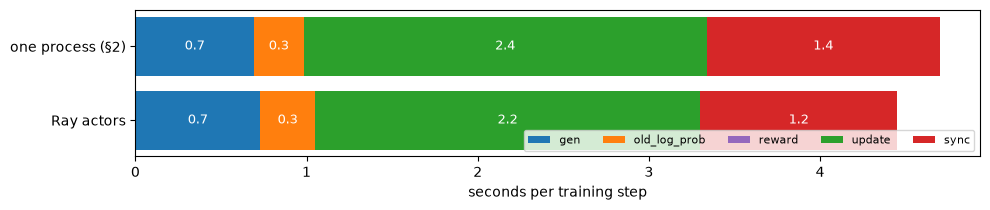

In [48]:
question_rng = random.Random(SEED)  # the same questions as the first steps of §2
ray_history = []
for step in range(10):
    problems = question_rng.sample(TRAIN, QUESTIONS_PER_STEP)
    metrics, last_batch = ray_rl_step(rollout_worker, training_worker, problems)
    ray_history.append(metrics)
    print_step_metrics(step, metrics)

plot_step_times({"one process (§2)": vllm_history[:10], "Ray actors": ray_history})

The reward rises as it did in §2, and the bar is about the same (about 4.4 s per step, against 4.7 s in one process): moving into separate processes costs almost nothing, as only the batch, the samples and the metrics travel through Ray. What Ray gives us isn't speed on one GPU, but structure: each role is now an independent process, with its own resources and lifetime, and the training loop is a plain Python loop on the driver. With more machines, the same code could place the two actors on different ones.

#### When one worker isn't enough

Each role is still a single process. That's fine for our reward, which is a regex. But many production rewards are slow: running a test suite, executing code in a sandbox, or calling a judge model. Let's make our reward check take 30 ms per sample, which is quick by those standards, and see what it does to a step:

In [49]:
SLOW_REWARD_SECONDS = 0.03  # stands in for a test run, a sandbox or a judge call


def slow_reward_fn(text: str, answer: int) -> float:
    time.sleep(SLOW_REWARD_SECONDS)
    return reward_fn(text, answer)

In [50]:
start = time.time()
slow_rewards = [slow_reward_fn(decode_tokens(row), int(answer))
                for row, answer in zip(last_batch.batch["responses"], last_batch.non_tensor_batch["answer"])]
reward_seconds = time.time() - start
print(f"scoring {len(slow_rewards)} samples on the driver: {reward_seconds:.1f}s")

scoring 128 samples on the driver: 3.9s


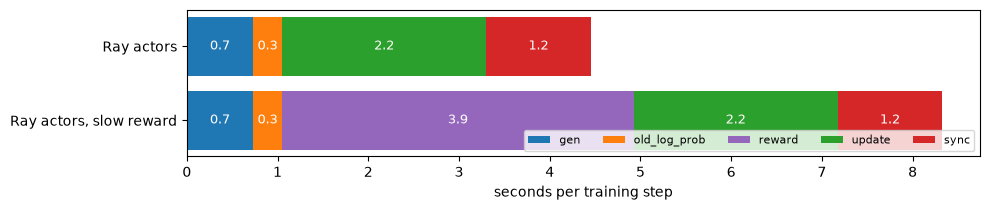

In [51]:
plot_step_times({"Ray actors": ray_history, "Ray actors, slow reward": [{**metrics, "time/reward": reward_seconds} for metrics in ray_history]})

Scoring the 128 samples now takes 3.9 s, almost as long as the rest of the step put together. The fix is to spread it over several processes: a **worker group**, N actors of the same class, along with a rule for each method that says how to split its input between the workers and how to combine their outputs. Two rules cover most of what a training loop needs:

![One-to-all: the driver sends the same call to every worker and gets back a list of results. Data-parallel: the batch is split into one chunk per worker, each worker processes its chunk, and the results are concatenated in order](images/worker_group.png)

* **One-to-all** sends the same call to every worker and returns all their results: for setup, such as loading a model.
* **Data-parallel** `chunk`s the `DataProto` into one piece per worker, and `concat`s their results back together, in order (§4): for the real work.

Our `ScoreWorker` scores its chunk of the batch with the slow reward:

In [52]:
@ray.remote(num_cpus=1)
class ScoreWorker:
    def __init__(self, rank: int, model: str):
        self.rank = rank
        self.tokenizer = AutoTokenizer.from_pretrained(model)

    def info(self) -> dict:
        return {"rank": self.rank, "pid": os.getpid()}

    def score(self, data: DataProto) -> DataProto:
        texts = self.tokenizer.batch_decode(data.batch["responses"], skip_special_tokens=True)
        rewards = torch.tensor([slow_reward_fn(text, int(answer)) for text, answer in zip(texts, data.non_tensor_batch["answer"])])
        return DataProto.from_dict(tensors={"reward": rewards}, non_tensors={"scored_by": np.full(len(data), self.rank, dtype=object)})


class MyWorkerGroup:
    def __init__(self, workers):
        self.workers = workers

    def one_to_all(self, method: str, *args):
        # Call the same method, with the same arguments, on every worker
        return ray.get([getattr(worker, method).remote(*args) for worker in self.workers])

    def data_parallel(self, method: str, data: DataProto) -> DataProto:
        # Split the batch into one chunk per worker, run the chunks in parallel, and concatenate the results
        chunks = data.chunk(len(self.workers))
        results = ray.get([getattr(worker, method).remote(chunk) for worker, chunk in zip(self.workers, chunks)])
        return DataProto.concat(results)

In [53]:
seconds_by_group_size = {}
for num_workers in [1, 2, 4, 8, 16]:
    score_group = MyWorkerGroup([ScoreWorker.remote(rank, MODEL) for rank in range(num_workers)])
    score_group.one_to_all("info")  # wait until every worker has started

    start = time.time()
    scored = score_group.data_parallel("score", last_batch)
    seconds_by_group_size[num_workers] = time.time() - start

    assert torch.equal(scored.batch["reward"], last_batch.batch["token_level_rewards"].sum(-1))  # same rewards, same order
    for worker in score_group.workers:
        ray.kill(worker)

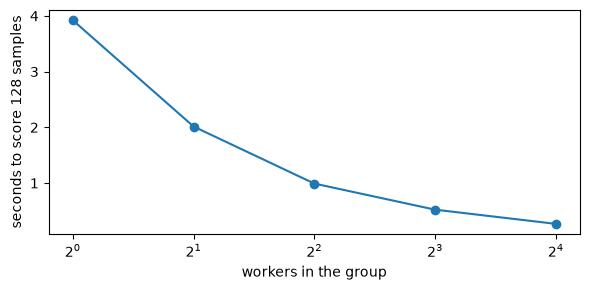

{1: 3.92, 2: 2.01, 4: 0.99, 8: 0.52, 16: 0.27}


In [54]:
plt.figure(figsize=(6, 3))
plt.plot(list(seconds_by_group_size), list(seconds_by_group_size.values()), marker="o")
plt.xscale("log", base=2)
plt.xlabel("workers in the group")
plt.ylabel("seconds to score 128 samples")
plt.tight_layout()
plt.show()
print({workers: round(seconds, 2) for workers, seconds in seconds_by_group_size.items()})

With 1 worker, scoring takes 3.9 s; with 16, 0.27 s, almost exactly 16 times faster, and every row comes back in its original order (the `assert` checks this for each group size). The same pattern scales the GPU roles too: a large policy is split across a group of training workers, and many vLLM engines generate in parallel. Workers that train the same model also need to talk to each other *directly*, many times per step (to share gradients, or gather the pieces of a model split across GPUs), which goes through a second channel, `torch.distributed`, rather than through the driver: Ray handles **which process runs what**, and `torch.distributed` the **data the workers exchange**.

#### verl's worker groups

verl packages this pattern up: instead of choosing a rule at each call, we **decorate each method with its rule** (its *dispatch mode*), and `RayWorkerGroup` gives the group a method of the same name that splits, calls and gathers for us:

| Ours | verl's |
|---|---|
| `group.one_to_all("info")` | `@register(dispatch_mode=Dispatch.ONE_TO_ALL)`, then `group.info()` |
| `group.data_parallel("score", batch)` | `@register(dispatch_mode=Dispatch.DP_COMPUTE_PROTO)`, then `group.score(batch)` |
| `rank` passed in by hand | `self.rank` and `self.world_size`, set by verl |
| a list of `ScoreWorker.remote(...)` | `RayResourcePool(process_on_nodes=[4])` |

In [55]:
from verl.single_controller.base import Worker
from verl.single_controller.base.decorator import Dispatch, register
from verl.single_controller.ray import RayClassWithInitArgs, RayResourcePool, RayWorkerGroup


class VerlScoreWorker(Worker):
    def __init__(self, model: str):
        super().__init__()
        self.tokenizer = AutoTokenizer.from_pretrained(model)

    @register(dispatch_mode=Dispatch.ONE_TO_ALL)
    def info(self) -> dict:
        return {"rank": self.rank, "world_size": self.world_size, "pid": os.getpid()}

    @register(dispatch_mode=Dispatch.DP_COMPUTE_PROTO)
    def score(self, data: DataProto) -> DataProto:
        texts = self.tokenizer.batch_decode(data.batch["responses"], skip_special_tokens=True)
        rewards = torch.tensor([slow_reward_fn(text, int(answer)) for text, answer in zip(texts, data.non_tensor_batch["answer"])])
        return DataProto.from_dict(tensors={"reward": rewards}, non_tensors={"scored_by": np.full(len(data), self.rank, dtype=object)})

In [56]:
pool = RayResourcePool(process_on_nodes=[4], use_gpu=False, max_colocate_count=4)
verl_score_group = RayWorkerGroup(resource_pool=pool, ray_cls_with_init=RayClassWithInitArgs(cls=ray.remote(VerlScoreWorker), model=MODEL))
print("info():", verl_score_group.info())

start = time.time()
verl_scored = verl_score_group.score(last_batch)
print(f"\nscored in {time.time() - start:.2f}s; same rewards as ours: {torch.equal(verl_scored.batch['reward'], scored.batch['reward'])}")
print("rows scored by each rank:", pd.Series(verl_scored.non_tensor_batch["scored_by"]).value_counts().sort_index().to_dict())

info(): [{'rank': 0, 'world_size': 4, 'pid': 188888}, {'rank': 1, 'world_size': 4, 'pid': 188889}, {'rank': 2, 'world_size': 4, 'pid': 188890}, {'rank': 3, 'world_size': 4, 'pid': 188891}]



scored in 1.10s; same rewards as ours: True
rows scored by each rank: {0: 32, 1: 32, 2: 32, 3: 32}


This is the core of verl's **single-controller** design: one driver runs the training loop and calls methods on worker groups. Its real workers are this same pattern with much more inside: `ActorRolloutRefWorker` holds a slice of the policy (split with FSDP or Megatron), its optimizer state and, colocated, a vLLM engine, with `init_model` one-to-all and `compute_log_prob` and `update_actor` data-parallel. Its driver, `RayPPOTrainer.fit()`, is our `ray_rl_step` in a loop. Going from 1 GPU to 64 changes the resource pools, not the training loop.

Let's stop everything, as verl will start its own Ray in the next section:

In [57]:
for worker in list(verl_score_group.workers):
    ray.kill(worker)
ray.get(rollout_worker.shutdown.remote())  # stop vLLM's engine process before its actor goes away
ray.shutdown()
time.sleep(5)
print(f"GPU free: {gpu_free_gib():.0f} GiB")

GPU free: 92 GiB


## 6. A real framework running the whole loop

We've now built every part of a production setup at a small scale. Let's hand our task to verl. What we have to provide is only what's specific to our task: a reward function, `compute_score`, which calls our `reward_fn`, and the data, as parquet files with one row per question.

In [58]:
%%writefile tutorial/generated/verl_reward.py
import os
import sys

sys.path.insert(0, os.path.join(os.path.dirname(os.path.dirname(os.path.abspath(__file__))), "lib"))
from arith_task import reward_fn  # noqa: E402


def compute_score(data_source, solution_str, ground_truth, extra_info=None, **kwargs):
    return reward_fn(solution_str, int(ground_truth))

Overwriting tutorial/generated/verl_reward.py


#### What do the settings count?

The trickiest part of a framework's config is the units, and getting them wrong silently changes the training. Our loop's step was 16 questions × 8 samples = 128 samples, in 2 mini-batches of 64, with micro-batches of 16 for π_old. In verl's settings, that is:

| Setting | Value | Counts | So it means |
|---|---|---|---|
| `data.train_batch_size` | 16 | **prompts** | 16 questions per step |
| `actor_rollout_ref.rollout.n` | 8 | samples per prompt | 16 × 8 = 128 samples |
| `actor_rollout_ref.actor.ppo_mini_batch_size` | 8 | **prompts**, multiplied by `n` | 8 × 8 = 64 samples: 2 optimizer steps per training step |
| `actor_rollout_ref.actor.ppo_micro_batch_size_per_gpu` | 16 | **samples** | 16 rows per forward and backward pass |

So the same word, "batch size", counts prompts in two places and samples in the third. Setting `ppo_mini_batch_size=64`, thinking in samples, would ask for 512 samples per mini-batch from a step that only has 128. The rest of the command maps onto what we built:

In [59]:
import datasets


def to_verl_rows(problems):
    rows = []
    for index, problem in enumerate(problems):
        rows.append({
            "data_source": "arith",
            "prompt": [{"role": "user", "content": f"{problem['question']} {INSTRUCTION}"}],
            "reward_model": {"style": "rule", "ground_truth": str(problem["answer"])},
            "extra_info": {"index": index},
        })
    return rows


datasets.Dataset.from_list(to_verl_rows(TRAIN[:512])).to_parquet(str(WORK / "arith_train.parquet"))
datasets.Dataset.from_list(to_verl_rows(EVAL[:64])).to_parquet(str(WORK / "arith_val.parquet"))

In [60]:
VERL_METRICS = WORK / "verl_metrics.jsonl"
VERL_METRICS.unlink(missing_ok=True)
verl_command = [
    sys.executable, "-m", "verl.trainer.main_ppo",
    "algorithm.adv_estimator=grpo",
    f"data.train_files={WORK / 'arith_train.parquet'}", f"data.val_files={WORK / 'arith_val.parquet'}",
    "data.train_batch_size=16", "data.max_prompt_length=256", "data.max_response_length=256", "data.dataloader_num_workers=0",
    f"actor_rollout_ref.model.path={MODEL}",
    "actor_rollout_ref.model.use_remove_padding=True", "actor_rollout_ref.model.enable_gradient_checkpointing=True",
    f"actor_rollout_ref.actor.optim.lr={LR}",
    "actor_rollout_ref.actor.ppo_mini_batch_size=8", "actor_rollout_ref.actor.ppo_micro_batch_size_per_gpu=16",
    "actor_rollout_ref.actor.use_kl_loss=False", "actor_rollout_ref.actor.entropy_coeff=0",
    "actor_rollout_ref.actor.clip_ratio_low=0.2", "actor_rollout_ref.actor.clip_ratio_high=0.28",
    "actor_rollout_ref.rollout.name=vllm", "actor_rollout_ref.rollout.tensor_model_parallel_size=1",
    "actor_rollout_ref.rollout.gpu_memory_utilization=0.4", "actor_rollout_ref.rollout.n=8",
    "actor_rollout_ref.rollout.log_prob_micro_batch_size_per_gpu=16",
    "actor_rollout_ref.rollout.agent.num_workers=2",
    f"reward.custom_reward_function.path={GENERATED / 'verl_reward.py'}", "reward.custom_reward_function.name=compute_score",
    "reward.num_workers=2",
    "trainer.n_gpus_per_node=1", "trainer.nnodes=1", "trainer.total_training_steps=10",
    "trainer.val_before_train=True", "trainer.test_freq=10", "trainer.save_freq=-1",
    "trainer.logger=[console,file]", "trainer.project_name=rl_training_series", "trainer.experiment_name=arith_verl",
    f"trainer.rollout_data_dir={WORK / 'verl_rollouts'}",
]
print(" \\\n  ".join(verl_command[2:]))

verl.trainer.main_ppo \
  algorithm.adv_estimator=grpo \
  data.train_files=/tmp/rl-from-scratch/arith_train.parquet \
  data.val_files=/tmp/rl-from-scratch/arith_val.parquet \
  data.train_batch_size=16 \
  data.max_prompt_length=256 \
  data.max_response_length=256 \
  data.dataloader_num_workers=0 \
  actor_rollout_ref.model.path=Qwen/Qwen2.5-0.5B-Instruct \
  actor_rollout_ref.model.use_remove_padding=True \
  actor_rollout_ref.model.enable_gradient_checkpointing=True \
  actor_rollout_ref.actor.optim.lr=2e-06 \
  actor_rollout_ref.actor.ppo_mini_batch_size=8 \
  actor_rollout_ref.actor.ppo_micro_batch_size_per_gpu=16 \
  actor_rollout_ref.actor.use_kl_loss=False \
  actor_rollout_ref.actor.entropy_coeff=0 \
  actor_rollout_ref.actor.clip_ratio_low=0.2 \
  actor_rollout_ref.actor.clip_ratio_high=0.28 \
  actor_rollout_ref.rollout.name=vllm \
  actor_rollout_ref.rollout.tensor_model_parallel_size=1 \
  actor_rollout_ref.rollout.gpu_memory_utilization=0.4 \
  actor_rollout_ref.rollou

| Config | What we built |
|---|---|
| `algorithm.adv_estimator=grpo` | `grpo_advantages` (§1.6 of the previous article) |
| `clip_ratio_low`/`high` | `ppo_clip_loss` (§1.9 of the previous article) |
| `rollout.name=vllm`, `gpu_memory_utilization` | `vllm_generate` and `RolloutWorker` (§1, §5) |
| `trainer.n_gpus_per_node`, `nnodes` | the resource pool (§5) |
| `reward.custom_reward_function`, `reward.num_workers` | `reward_fn`, in a group of reward workers (§5) |
| `model.use_remove_padding=True` | new: rather than padding rows into a rectangle, verl packs every row's real tokens into one long sequence, so no compute is spent on padding |

Most of the run's time is spent starting up: Ray, the policy (wrapped in FSDP), and vLLM, which captures its CUDA graphs. Only selected lines of verl's log are printed; the full log is in `/tmp/rl-from-scratch/logs/arith_verl.log`.

In [61]:
start_service("arith_verl", verl_command, cwd=WORK, env={"VERL_FILE_LOGGER_PATH": str(VERL_METRICS), "WANDB_MODE": "disabled"})
exit_code = follow_log("arith_verl", r"step:\d+ |Initial validation|Training Progress")
print(f"\nverl exited with code {exit_code}")
if exit_code != 0:
    raise RuntimeError(log_tail("arith_verl", 60))

started arith_verl (pid 189218), log: /tmp/rl-from-scratch/logs/arith_verl.log


[   86s] (TaskRunner pid=192313) ("Initial validation metrics: {'val-aux/arith/reward/mean@1': "
[   86s] (TaskRunner pid=192313) step:0 - val-aux/arith/reward/mean@1:np.float64(0.734375) - val-core/arith/acc/mean@1:np.float64(0.734375) - val-aux/num_turns/min:np.int32(2) - val-aux/num_turns/max:np.int32(2) - val-aux/num_tur …
[   86s] (TaskRunner pid=192313) step:1 - global_seqlen/min:26834 - global_seqlen/max:26834 - global_seqlen/minmax_diff:0 - global_seqlen/balanced_min:26834 - global_seqlen/balanced_max:26834 - global_seqlen/mean:26834.0 - actor/ …
[   86s] (TaskRunner pid=192313) step:2 - global_seqlen/min:25462 - global_seqlen/max:25462 - global_seqlen/minmax_diff:0 - global_seqlen/balanced_min:25462 - global_seqlen/balanced_max:25462 - global_seqlen/mean:25462.0 - actor/ …


[   97s] (TaskRunner pid=192313) step:3 - global_seqlen/min:25803 - global_seqlen/max:25803 - global_seqlen/minmax_diff:0 - global_seqlen/balanced_min:25803 - global_seqlen/balanced_max:25803 - global_seqlen/mean:25803.0 - actor/ …
[   97s] (TaskRunner pid=192313) step:4 - global_seqlen/min:26562 - global_seqlen/max:26562 - global_seqlen/minmax_diff:0 - global_seqlen/balanced_min:26562 - global_seqlen/balanced_max:26562 - global_seqlen/mean:26562.0 - actor/ …
[   97s] (TaskRunner pid=192313) step:5 - global_seqlen/min:27998 - global_seqlen/max:27998 - global_seqlen/minmax_diff:0 - global_seqlen/balanced_min:27998 - global_seqlen/balanced_max:27998 - global_seqlen/mean:27998.0 - actor/ …


[  108s] (TaskRunner pid=192313) step:6 - global_seqlen/min:23248 - global_seqlen/max:23248 - global_seqlen/minmax_diff:0 - global_seqlen/balanced_min:23248 - global_seqlen/balanced_max:23248 - global_seqlen/mean:23248.0 - actor/ …
[  108s] (TaskRunner pid=192313) step:7 - global_seqlen/min:22964 - global_seqlen/max:22964 - global_seqlen/minmax_diff:0 - global_seqlen/balanced_min:22964 - global_seqlen/balanced_max:22964 - global_seqlen/mean:22964.0 - actor/ …
[  108s] (TaskRunner pid=192313) step:8 - global_seqlen/min:22967 - global_seqlen/max:22967 - global_seqlen/minmax_diff:0 - global_seqlen/balanced_min:22967 - global_seqlen/balanced_max:22967 - global_seqlen/mean:22967.0 - actor/ …


[  115s] (TaskRunner pid=192313) step:9 - global_seqlen/min:22992 - global_seqlen/max:22992 - global_seqlen/minmax_diff:0 - global_seqlen/balanced_min:22992 - global_seqlen/balanced_max:22992 - global_seqlen/mean:22992.0 - actor/ …


[  117s] (TaskRunner pid=192313) step:10 - global_seqlen/min:21612 - global_seqlen/max:21612 - global_seqlen/minmax_diff:0 - global_seqlen/balanced_min:21612 - global_seqlen/balanced_max:21612 - global_seqlen/mean:21612.0 - actor …



verl exited with code 0


#### Reading verl's run with our tools

verl logs a few hundred metrics per step, one JSON line per step. Let's read back the ones that match what our own loop measured, and put verl's timings into the same step-time bar as our setups:

In [62]:
def read_metrics(path: Path, patterns: list[str]) -> pd.DataFrame:
    # verl's file logger writes one JSON line per step; keep the metrics whose names match any pattern, in pattern order
    records = [json.loads(line) for line in path.read_text().splitlines()]
    all_names = sorted({name for record in records for name in record["data"]})
    keep = []
    for pattern in patterns:
        for name in all_names:
            if re.fullmatch(pattern, name) and name not in keep:
                keep.append(name)
    rows = [{"step": record["step"], **{name: record["data"].get(name) for name in keep}} for record in records]
    return pd.DataFrame(rows).groupby("step").last()


read_metrics(VERL_METRICS, [
    r"val-core/.*mean@1", r"critic/score/mean", r"actor/pg_loss", r"actor/grad_norm", r"actor/ppo_kl", r"actor/pg_clipfrac",
    r"actor/entropy", r"rollout_corr/.*", r"response_length/mean", r"timing_s/(gen|reward|old_log_prob|update_actor|update_weights|step)",
]).T

step,0,1,2,3,4,5,6,7,8,9,10
val-core/arith/acc/mean@1,0.734375,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.781250
critic/score/mean,NaN,0.625000,0.585938,0.648438,0.500000,0.531250,0.773438,0.859375,0.687500,0.898438,0.757812
actor/pg_loss,NaN,0.050834,0.017936,0.068669,0.052110,0.076724,-0.011681,0.032876,-0.001727,0.011068,0.000332
actor/grad_norm,NaN,2.463560,2.343802,2.179628,1.852708,1.622147,1.814146,1.818338,1.611107,1.844642,1.346409
actor/ppo_kl,NaN,0.000214,0.000038,0.000673,0.000110,0.000072,0.000416,0.000077,0.000004,-0.000207,0.000176
actor/pg_clipfrac,NaN,0.000543,0.000187,0.001529,0.000443,0.000370,0.000901,0.000140,0.000354,0.000394,0.000294
actor/entropy,NaN,0.325937,0.356423,0.290359,0.261751,0.269866,0.194924,0.189857,0.188008,0.151811,0.158382
response_length/mean,NaN,151.890625,141.421875,144.210938,149.828125,160.921875,124.375000,121.843750,122.054688,121.875000,111.718750
timing_s/gen,NaN,1.039338,1.016675,1.019821,1.020329,1.038999,0.992487,0.998472,0.996484,0.901567,0.988367
timing_s/old_log_prob,NaN,1.268680,0.494079,0.474312,0.467729,0.484987,0.462766,0.459745,0.461591,0.455635,0.456748


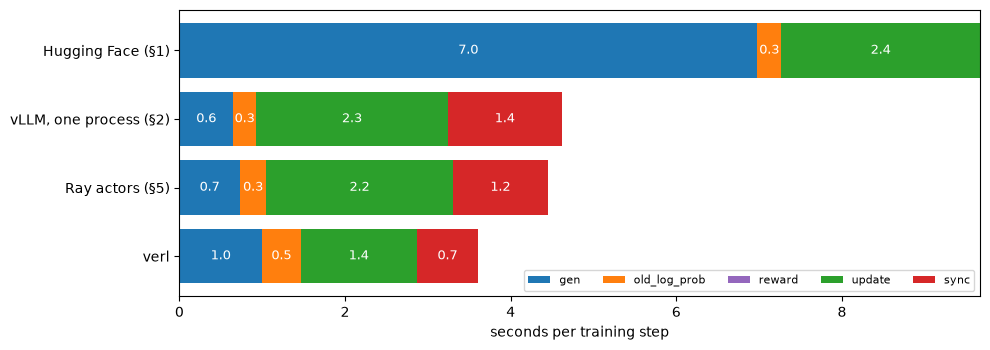

In [63]:
verl_records = [json.loads(line) for line in VERL_METRICS.read_text().splitlines()]
verl_history = []
for record in verl_records[2:]:  # skip the validation record and the first step, which includes warm-up
    timings = record["data"]
    if "timing_s/gen" not in timings:
        continue
    verl_history.append({
        "time/gen": timings.get("timing_s/gen", 0.0),
        "time/reward": timings.get("timing_s/reward", 0.0),
        "time/old_log_prob": timings.get("timing_s/old_log_prob", 0.0),
        "time/update": timings.get("timing_s/update_actor", 0.0),
        "time/sync": timings.get("timing_s/update_weights", 0.0),
    })

plot_step_times({"Hugging Face (§1)": hf_history, "vLLM, one process (§2)": vllm_history, "Ray actors (§5)": ray_history, "verl": verl_history})

verl's run tells the same story as ours. Accuracy on the 64 held-out questions went from 0.73 to 0.78, and the training reward rose from about 0.6 to around 0.8–0.9, noisily. `actor/ppo_kl` and `actor/pg_clipfrac` are small but not zero, as each step takes two optimizer steps, and the second one sees ratios away from 1. `actor/entropy`, which we never measured, falls from about 0.33 to 0.16 as the model becomes more confident; if it collapsed towards 0, the groups would stop containing different answers to compare. verl only logs `rollout_corr/kl` when `algorithm.rollout_correction` is turned on, which is why it isn't in the table.

In the step-time bar (leaving out the first step, which includes warm-up), verl takes about 3.7 s per step: about 1 s generating, 0.5 s on π_old, 1.4 s updating and 0.75 s syncing the weights. Its update is faster than ours, helped by packing the sequences without padding, and so is its weight sync, which skips the round trip through the CPU; its generation is a little slower, as it goes through more machinery than a single `llm.generate` call.

`trainer.rollout_data_dir` also makes verl save every sample it generated, with its score. When a metric moves unexpectedly, reading what the model actually wrote is usually the quickest way to find out why:

In [64]:
def step_number(path: Path) -> int:
    return int(path.stem)


rollout_files = sorted((WORK / "verl_rollouts").glob("*.jsonl"), key=step_number)  # one file per training step
for path in rollout_files:
    scores = [json.loads(line)["score"] for line in path.read_text().splitlines()]
    print(f"training step {path.stem:>2}: {len(scores)} samples, mean score {np.mean(scores):.2f}")

example = json.loads(rollout_files[-1].read_text().splitlines()[0])
print("\n" + "─" * 100 + "\n" + example["output"] + f"\n{'─' * 100}\nground truth {example['gts']} | score {example['score']}")

training step  1: 128 samples, mean score 0.62
training step  2: 128 samples, mean score 0.59
training step  3: 128 samples, mean score 0.65
training step  4: 128 samples, mean score 0.50
training step  5: 128 samples, mean score 0.53
training step  6: 128 samples, mean score 0.77
training step  7: 128 samples, mean score 0.86
training step  8: 128 samples, mean score 0.69
training step  9: 128 samples, mean score 0.90
training step 10: 128 samples, mean score 0.76

────────────────────────────────────────────────────────────────────────────────────────────────────
First, we need to perform the operation in the order it is given: multiplication and addition.
81 + 11 * 7 = 81 + 77 = \boxed{158}.
────────────────────────────────────────────────────────────────────────────────────────────────────
ground truth 158 | score 1.0


## What we built

| What goes wrong without it | Fix | Ours | verl's |
|---|---|---|---|
| generation takes most of each step | a dedicated inference engine | `vllm_generate` | vLLM, started by verl |
| the engine samples from the chat defaults, not π | pass the RL sampling settings | `rl_settings` | verl overrides the generation config |
| the engine's weights fall behind, silently | push the weights after every update, reset the prefix cache | `push_weights` | GPU-to-GPU transfer over CUDA IPC or NCCL |
| the engine's log-probs differ from the training model's, so the clip blocks updates that never happened | recompute π_old with the training model, and monitor the gap | `compute_log_probs`, `logp_mismatch` | `compute_log_prob`, `rollout_corr/kl` |
| reordering a batch misaligns its side lists | a batch container that keeps each row together | `DataProto` | `DataProto` |
| the roles need different memory at different times | separate processes; vLLM sleeps during the update | Ray actors, `llm.sleep` | `RayPPOTrainer`, the hybrid engine |
| one process per role is too slow | worker groups, with one rule per method for splitting the work | `MyWorkerGroup` | `RayWorkerGroup`, `@register(Dispatch...)` |

For a single-turn task like ours, that's the whole story: with verl, the only code we had to write was the reward function and the data.

#### What changes at scale

Everything here ran a 0.5B model on one GPU, so it's fair to ask what changes with a 7B or 70B model on many GPUs. The training step itself doesn't: π_old is still recomputed, the advantages and the clipped loss are the same, the batch still travels as a `DataProto`, and a single driver still calls worker groups. What changes is what sits inside each piece:

* **The policy no longer fits on one GPU.** Each training worker holds a shard of it (with FSDP, or Megatron's tensor and pipeline parallelism), so `compute_log_prob` and `update_actor` become collective operations across a group, and vLLM splits each engine across several GPUs too, with many engines generating in parallel.
* **The weight sync becomes expensive.** Instead of one file in `/dev/shm`, the training workers' shards have to be gathered, converted to the inference engines' layout, and sent to every engine, over NCCL, after every update. For large models, this is one of the main costs of a step. Microsoft AI's Rocket, for example, gets it to about 15 seconds for a 3-trillion-parameter model by having a few engines pull the weights from the training workers and pass them on to the rest.
* **Generation dominates again.** Responses grow from about 150 tokens to thousands, and their lengths vary much more, so the longest response holds up the whole batch. This is where asynchronous training and the disaggregated layout start to pay off.
* **The mismatch grows.** Longer sequences, and mixture-of-experts models, where the two engines can route a token to different experts, make the gap between the training model and vLLM larger, so corrections like truncated importance sampling (§3) go from optional to routine. Precision gets harder too: to fit a larger model in the inference engine, Rocket stores most of its weights in 8 bits, and makes the training model round its own copy of those weights the same way, so the two still agree.

So, the questions this article asked are the same at any scale; the answers just get more expensive to get wrong.

**Next steps:** there is one stage of the training step that we haven't questioned yet: where the samples come from. So far, every sample has been a single response to a single prompt. Agents work differently: they call tools, read the results and carry on over many turns, and they're often programs that already exist, with their own code and their own way of talking to the model. That is the subject of the next article.

In [65]:
shutil.rmtree(SHM, ignore_errors=True)  # the weights we wrote for vLLM
print(f"GPU free: {gpu_free_gib():.0f} GiB")

GPU free: 92 GiB
